# From stochastic paths to the Fokker–Planck density

An SDE evolves individual paths, whereas the Fokker–Planck equation
evolves their probability density. Constant drift and diffusion admit an
analytical Gaussian density against which an ensemble can be tested.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Ensemble simulation

A large one-dimensional ensemble is advanced by Euler–Maruyama. Positions are
stored only at selected times to control memory use.


In [2]:
rng = np.random.default_rng(62707)
path_count = 120_000
drift = 0.55
diffusivity = 0.35
time_step = 0.005
step_count = 600
sample_steps = np.array([100, 200, 400, 600])
sample_times = sample_steps * time_step
position = np.zeros(path_count)
sampled_position = {}

for step in range(1, step_count + 1):
    position += (
        drift * time_step
        + np.sqrt(2.0 * diffusivity * time_step)
        * rng.standard_normal(path_count)
    )
    if step in sample_steps:
        sampled_position[step] = position.copy()

def gaussian_density(coordinate, time_value):
    variance = 2.0 * diffusivity * time_value
    mean = drift * time_value
    return np.exp(-(coordinate - mean) ** 2 / (2.0 * variance)) / np.sqrt(
        2.0 * np.pi * variance
    )


## Verification

Histogram densities are compared with the analytical Fokker–Planck solution
using an integrated absolute error.


In [3]:
density_errors = []
histogram_data = []
for step, time_value in zip(sample_steps, sample_times, strict=True):
    values = sampled_position[int(step)]
    histogram, edges = np.histogram(values, bins=100, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    theory = gaussian_density(centers, time_value)
    error = np.sum(np.abs(histogram - theory) * np.diff(edges))
    density_errors.append(error)
    histogram_data.append((histogram, edges, centers, theory))

assert max(density_errors) < 0.045
print("integrated density errors:", np.array(density_errors))


integrated density errors: [0.01482317 0.0178183  0.01702726 0.01586677]


## Instructive plot

Every panel compares a path-ensemble histogram with the density obtained from
the Fokker–Planck equation. Agreement improves the distinction between a
trajectory description and a density description.


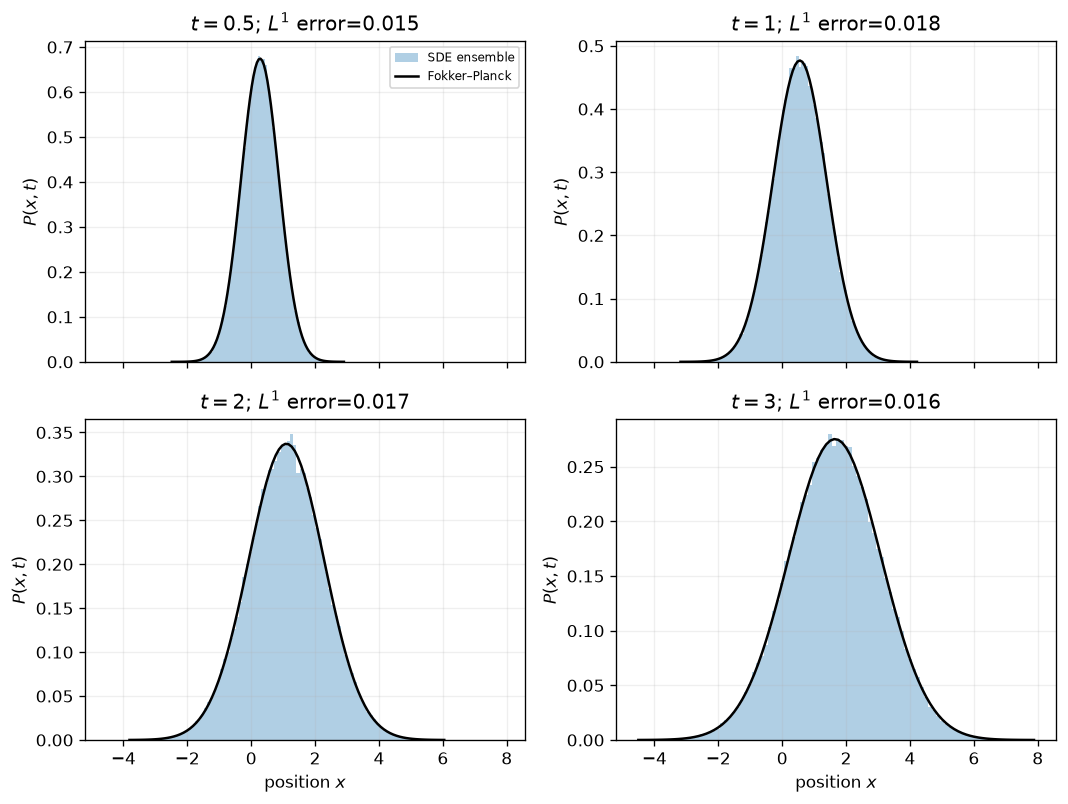

wrote lecture-notes/figures/08_brownian-motion-diffusion/07-sde-to-fokker-planck.pdf


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(9.0, 6.8), sharex=True)

for axis, time_value, data, error in zip(
    axes.flat,
    sample_times,
    histogram_data,
    density_errors,
    strict=True,
):
    histogram, edges, centers, theory = data
    axis.stairs(histogram, edges, fill=True, alpha=0.35, label="SDE ensemble")
    axis.plot(centers, theory, color="black", linewidth=1.5, label="Fokker–Planck")
    axis.set(title=rf"$t={time_value:g}$; $L^1$ error={error:.3f}", ylabel=r"$P(x,t)$")
    axis.grid(alpha=0.2)

for axis in axes[-1]:
    axis.set_xlabel(r"position $x$")
axes[0, 0].legend(fontsize=7)
figure.tight_layout()
output_path = OUTPUT / "07-sde-to-fokker-planck.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
